# Classification Models

## Discussion questions

Suppose you are developing a classification model to determine whether or not a person has a particular disease (based on symptoms, results of diagnostic tests, family history, risk factors, etc).

1. Explain what "precision" represents in this context.

Precision in this case would be the number of cases the model called positive divided by the amount that is actually positive.

**Discuss with your partner, and make notes here.**



2. Explain what "recall" represents in this context.

Recall in this case would be the number of cases that actually have cancer, were actually labelled as cancer

3. Which of the following do you think is a more serious error? It's an opinion question, but choose one and discuss.

- Concluding that a person has the disease if they actually don't have it
- Failing to conclude that a person has the disease if they actually do have it

Missing someone who has the disease is more serious because it could delay treatment.

4. Given your answer to the previous question, which would you prefer to be higher: precision or recall?

I would prefer higher recall because it means fewer cases are missed.

5. Suppose you want to achieve higher recall. Should your classification rule be more or less strict about who it predicts to have the disease?

The rule should be less strict so more people are predicted to have the disease.

6. What is a downside to your choice in the previous part?

More people without the disease could be incorrectly labeled positive.

In [38]:
import pandas as pd
import numpy as np

## More wine

The wines data set (https://dlsun.github.io/pods/data/wines.csv ) contains data about the chemical composition of various wines. We'll first use just two features&mdash;fixed acidity and volatile acidity&mdash;to predict the color of the wine (red or white).

In [39]:
df_train = pd.read_csv("https://dlsun.github.io/pods/data/wines.csv")

df_train

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


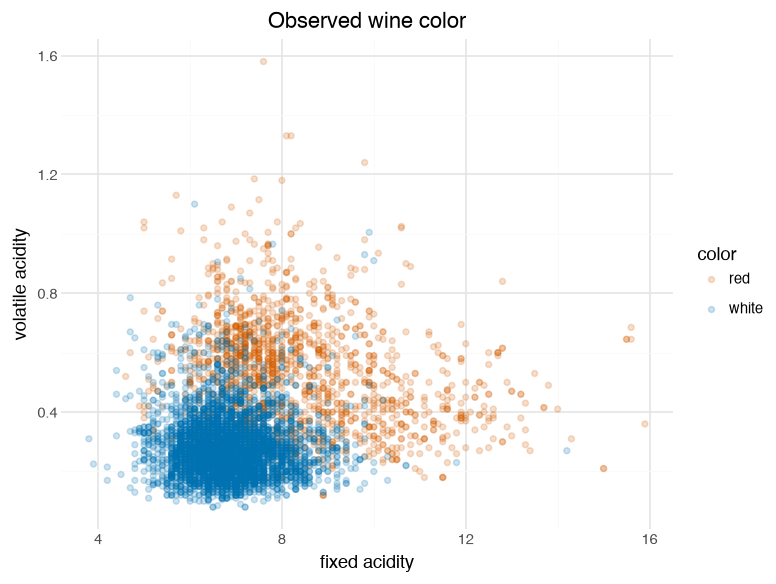

In [40]:
from plotnine import *

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Observed wine color")
    + theme_minimal()
)

1\. Fit a 15-nearest neighbors model for predicting color from fixed acidity and volatile acidity. Don't forget to scale the features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the observed colors.

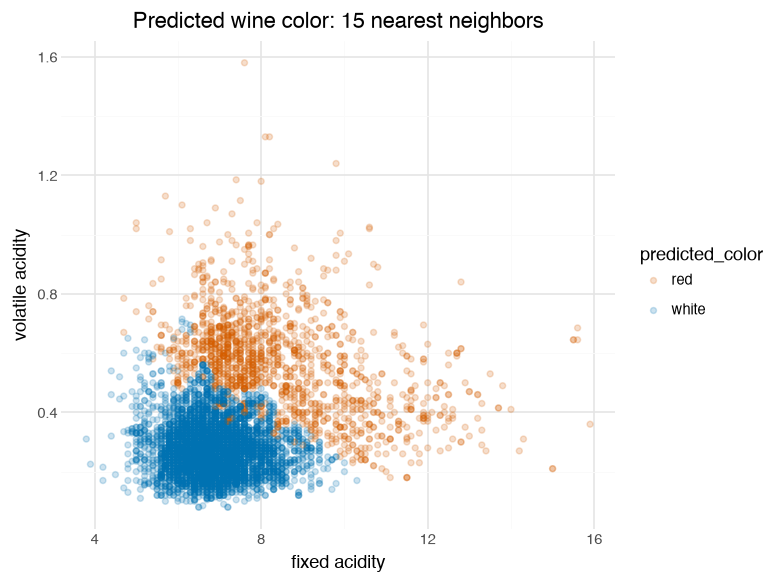

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X = df_train[["fixed acidity", "volatile acidity"]]
y = df_train["color"]

knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=15))
])

knn.fit(X, y)

df_knn = df_train.copy()
df_knn["predicted_color"] = knn.predict(X)

(
    ggplot(df_knn, aes(x="fixed acidity", y="volatile acidity", color="predicted_color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color: 15 nearest neighbors")
    + theme_minimal()
)

2\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score using `macro` scoring.

In [42]:
from sklearn.model_selection import cross_validate

scoring = {
    "Precision": "precision_macro",
    "Recall": "recall_macro",
    "F1": "f1_macro"
}

knn_scores = cross_validate(knn, X, y, cv=10, scoring=scoring)

knn_results = pd.Series({
    metric: knn_scores[f"test_{metric}"].mean()
    for metric in scoring
})

knn_results

Precision    0.881381
Recall       0.854369
F1           0.863297
dtype: float64

3\. Use `GridSearchCV` to fit $k$-nearest neighbors models for $k=1,\ldots, 30$ and use cross validation to estimate the test F1 macro score. Plot the test score versus $k$. Which value of $k$ yields the best score?

Best k: 16
Best F1 macro score: 0.8664272356440673


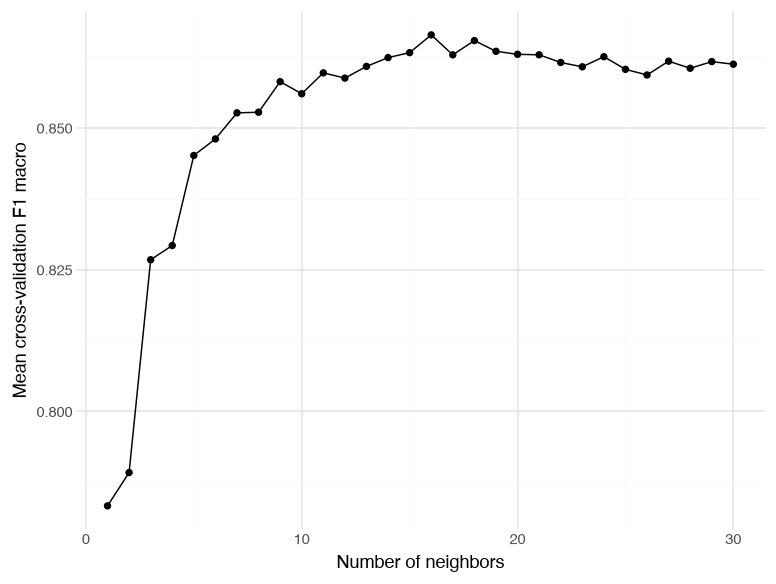

In [43]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    knn,
    {"model__n_neighbors": range(1, 31)},
    scoring="f1_macro",
    cv=10
)

grid.fit(X, y)

grid_results = pd.DataFrame({
    "k": list(range(1, 31)),
    "F1": grid.cv_results_["mean_test_score"]
})

print("Best k:", grid.best_params_["model__n_neighbors"])
print("Best F1 macro score:", grid.best_score_)

(
    ggplot(grid_results, aes(x="k", y="F1"))
    + geom_line()
    + geom_point()
    + labs(x="Number of neighbors", y="Mean cross-validation F1 macro")
    + theme_minimal()
)

4\. When the target variable is binary **logistic regression** provides another classification algorithm.

Fit a logistic regression model for predicting wine color from the two features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the predictions from the nearest neighbors classifier.

Note: with regression, you don't need to scale the features (unless you add a penalty). Hint: you basically just need to replace with `KNeighborsClassifier()` with `LogisticRegression()`.

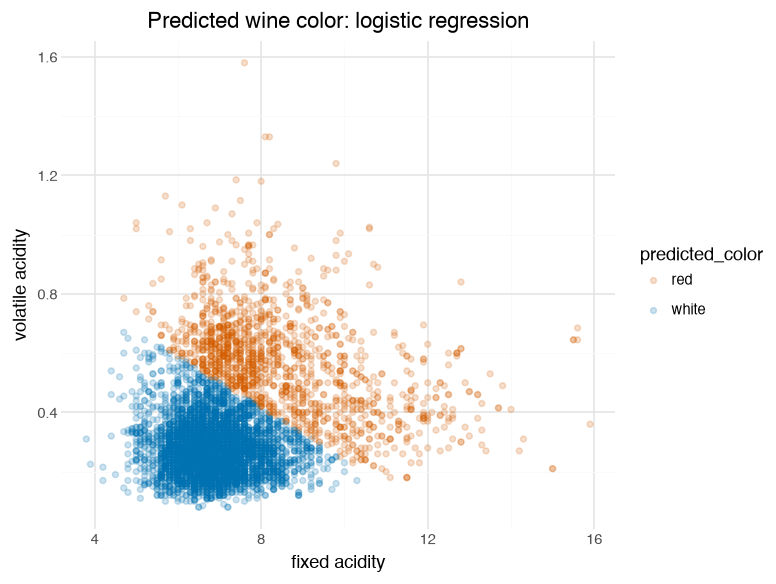

In [44]:
from sklearn.linear_model import LogisticRegression

logistic = LogisticRegression(C=np.inf, max_iter=10000)
logistic.fit(X, y)

df_logistic = df_train.copy()
df_logistic["predicted_color"] = logistic.predict(X)

(
    ggplot(df_logistic, aes(x="fixed acidity", y="volatile acidity", color="predicted_color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color: logistic regression")
    + theme_minimal()
)

5\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring. Compare to the nearest neighbors model.

In [45]:
logistic = LogisticRegression(C=np.inf, max_iter=10000)


logistic_scores = cross_validate(
    logistic, X, y, cv=10, scoring=scoring
)

logistic_results = pd.Series({
    metric: logistic_scores[f"test_{metric}"].mean()
    for metric in scoring
})

comparison = pd.DataFrame({
    "15-nearest neighbors": knn_results,
    "Logistic regression": logistic_results
})

display(comparison)

print("Higher F1:", comparison.loc["F1"].idxmax())

,15-nearest neighbors,Logistic regression
Precision,0.881381,0.891696
Recall,0.854369,0.852187
F1,0.863297,0.864589


Higher F1: Logistic regression


6\. Now fit a logistic regression model using all of the potential predictors. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [46]:
X_all = df_train.drop(columns="color")


logistic_all = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=np.inf, max_iter=10000))
])

all_scores = cross_validate(
    logistic_all, X_all, y, cv=10, scoring=scoring
)

all_results = pd.Series({
    metric: all_scores[f"test_{metric}"].mean()
    for metric in scoring
})

logistic_all.fit(X_all, y)

all_results

Precision    0.992344
Recall       0.989403
F1           0.990838
dtype: float64

7\. Now fit a logistic regression model using all of the potential predictors with a LASSO (`"l1"`) penalty. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [47]:
lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        l1_ratio=1,
        solver="liblinear",
        max_iter=10000,
        random_state=42
    ))
])
lasso_scores = cross_validate(
    lasso, X_all, y, cv=10, scoring=scoring
)

lasso_results = pd.Series({
    metric: lasso_scores[f"test_{metric}"].mean()
    for metric in scoring
})

lasso.fit(X_all, y)

pd.DataFrame({
    "All predictors": all_results,
    "LASSO": lasso_results
})

,All predictors,LASSO
Precision,0.992344,0.992155
Recall,0.989403,0.990449
F1,0.990838,0.991268
